# Lab 2 — Anomaly Detection in Account Logins

## 1. Scenario and Dataset Plan

**Objective:** Compare Isolation Forest and an autoencoder with categorical embeddings for detecting suspicious account logins.

**Observation unit:** One successful login, including a simulated count of preceding failed attempts and earlier device usage.

The dataset represents 20 employees who normally work Sunday–Thursday, between 08:00 and 18:00, using a laptop or phone. Legitimate exceptions include evening and nighttime work, new laptops, and incorrect password attempts before a successful login.

The main attack scenario involves an adversary using stolen credentials, corresponding to MITRE ATT&CK T1078 — Valid Accounts. Some routine-like attacks additionally assume access through an existing device or session context. Reusing a device identifier is a simulation assumption, not proof of a particular compromise mechanism. Unusual timing, a new device, or failed attempts alone do not establish that a login is malicious.

The synthetic data cover:
- 30 days of legitimate warm-up history (2,000 events);
- 60 days of experimental events;
- 4,000 experimental records, including 120 attacks (3%).

Model features are login time, weekend status, failed attempts during the preceding 30 minutes, prior device logins during the preceding 30 days, and device type.

The failed_attempts_30m field is sampled for each scenario rather than computed from separate failed-login logs. Its distribution differs by scenario by construction. In contrast, prior_device_logins_30d is calculated from strictly earlier successful logins of the same account-device pair, using the interval [t - 30 days, t). Events with identical timestamps do not count one another.

Attack labels are excluded from model inputs. They are used to select normal-only autoencoder training/validation records, evaluate detection results, and select contrasting examples for retrospective error analysis.

**Assignment source:** [Official Lab 2 README](https://github.com/melofon/HIT-ai-cybersecurity-labs/blob/main/labs/lab2%20Anomaly%20Detection/README.md). The experiment compares the two required methods and retains analyst review as a separate step.


In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

SEED = 42
rng = np.random.default_rng(SEED)

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("Environment ready.")

Python: 3.13.18
NumPy: 2.4.6
pandas: 2.2.3
scikit-learn: 1.6.1
Environment ready.


In [2]:
# Dataset configuration
N_USERS = 20
WARMUP_DAYS = 30
EXPERIMENT_DAYS = 60

N_WARMUP = 2000
N_EXPERIMENT = 4000
N_ATTACK = 120
N_NORMAL = N_EXPERIMENT - N_ATTACK

START_DATE = pd.Timestamp("2026-08-02")

# pandas weekday numbering: Monday=0, ..., Sunday=6
WORKDAYS = {6, 0, 1, 2, 3}  # Sunday–Thursday
WEEKEND_DAYS = {4, 5}        # Friday–Saturday

WORK_START = 8
WORK_END = 18

users = [f"user_{i:02d}" for i in range(1, N_USERS + 1)]

assert N_NORMAL + N_ATTACK == N_EXPERIMENT
assert 0.01 <= N_ATTACK / N_EXPERIMENT <= 0.05

print("Employees:", N_USERS)
print("Warm-up:", N_WARMUP, "normal logins over", WARMUP_DAYS, "days")
print("Experiment:", N_EXPERIMENT, "logins over", EXPERIMENT_DAYS, "days")
print("Normal experimental logins:", N_NORMAL)
print("Attack logins:", N_ATTACK)
print(f"Attack proportion: {N_ATTACK / N_EXPERIMENT:.1%}")

Employees: 20
Warm-up: 2000 normal logins over 30 days
Experiment: 4000 logins over 60 days
Normal experimental logins: 3880
Attack logins: 120
Attack proportion: 3.0%


In [3]:
# Generate legitimate logins, including unusual but authorized activity.
normal_rng = np.random.default_rng(SEED)

experiment_start = START_DATE + pd.Timedelta(days=WARMUP_DAYS)

# Each employee receives a replacement laptop during the experiment.
replacement_dates = {
    user: experiment_start + pd.Timedelta(
        days=int(normal_rng.integers(15, 45))
    )
    for user in users
}


def generate_normal_logins(n, start, days, phase):
    rows = []

    for _ in range(n):
        user = str(normal_rng.choice(users))

        # Most legitimate activity occurs on working days.
        while True:
            date = start + pd.Timedelta(
                days=int(normal_rng.integers(0, days))
            )
            if date.dayofweek in WORKDAYS or normal_rng.random() < 0.08:
                break

        pattern = str(normal_rng.choice(
            ["routine", "evening_work", "night_work"],
            p=[0.92, 0.07, 0.01]
        ))

        if pattern == "routine":
            minute_of_day = int(normal_rng.integers(8 * 60, 18 * 60))
        elif pattern == "evening_work":
            minute_of_day = int(normal_rng.integers(18 * 60, 22 * 60))
        else:
            minute_of_day = int(normal_rng.integers(0, 6 * 60))

        timestamp = date + pd.Timedelta(minutes=minute_of_day)

        device_type = str(normal_rng.choice(
            ["laptop", "phone"], p=[0.85, 0.15]
        ))

        if device_type == "phone":
            device_id = f"{user}_phone"
        elif timestamp >= replacement_dates[user]:
            device_id = f"{user}_laptop_new"
        else:
            device_id = f"{user}_laptop_original"

        # Several mistakes can also occur during legitimate activity.
        failed_attempts = int(normal_rng.choice(
            [0, 1, 2, 3, 4, 5],
            p=[0.60, 0.28, 0.07, 0.03, 0.015, 0.005]
        ))

        rows.append({
            "timestamp": timestamp,
            "user_id": user,
            "device_id": device_id,
            "device_type": device_type,
            "failed_attempts_30m": failed_attempts,
            "phase": phase,
            "scenario": pattern,
            "is_attack": 0,
        })

    return pd.DataFrame(rows)


warmup_df = generate_normal_logins(
    N_WARMUP, START_DATE, WARMUP_DAYS, "warmup"
)

normal_df = generate_normal_logins(
    N_NORMAL, experiment_start, EXPERIMENT_DAYS, "experiment"
)

# Include the student's authorized new-laptop example explicitly.
example_user = users[0]
example_date = replacement_dates[example_user]

# Move to the next working day if necessary.
while example_date.dayofweek not in WORKDAYS:
    example_date += pd.Timedelta(days=1)

normal_df.loc[0, [
    "timestamp", "user_id", "device_id", "device_type",
    "failed_attempts_30m", "scenario"
]] = [
    example_date + pd.Timedelta(hours=18, minutes=20),
    example_user,
    f"{example_user}_laptop_replacement_example",
    "laptop",
    2,
    "authorized_new_laptop",
]

print("Warm-up normal logins:", len(warmup_df))
print("Experimental normal logins:", len(normal_df))
print("\nAuthorized exception:")
display(normal_df.loc[[0]])

print("\nLegitimate activity patterns:")
print(normal_df["scenario"].value_counts())

Warm-up normal logins: 2000
Experimental normal logins: 3880

Authorized exception:


,timestamp,user_id,device_id,device_type,failed_attempts_30m,phase,scenario,is_attack
0,2026-09-20 18:20:00,user_01,user_01_laptop_replacement_example,laptop,2,experiment,authorized_new_laptop,0



Legitimate activity patterns:
scenario
routine                  3556
evening_work              283
night_work                 40
authorized_new_laptop       1
Name: count, dtype: int64


In [4]:
# Generate successful logins made by an adversary using stolen credentials.
attack_rng = np.random.default_rng(SEED + 1)

attack_scenarios = np.repeat(
    ["night_intrusion", "unfamiliar_device", "routine_like_attack"],
    N_ATTACK // 3
)
attack_rng.shuffle(attack_scenarios)

attack_rows = []

for i, scenario in enumerate(attack_scenarios):
    user = str(attack_rng.choice(users))
    date = experiment_start + pd.Timedelta(
        days=int(attack_rng.integers(0, EXPERIMENT_DAYS))
    )

    device_type = str(attack_rng.choice(["laptop", "phone"]))
    device_id = f"{user}_unfamiliar_{i:03d}"

    if scenario == "night_intrusion":
        minute = int(attack_rng.integers(0, 6 * 60))
        failures = int(attack_rng.integers(2, 7))

    elif scenario == "unfamiliar_device":
        minute = int(attack_rng.integers(7 * 60, 22 * 60))
        failures = int(attack_rng.choice([0, 1, 2, 3]))

    else:
        # Some attacks imitate routine activity, including working days.
        while date.dayofweek not in WORKDAYS:
            date -= pd.Timedelta(days=1)
            if date < experiment_start:
                date = experiment_start

        minute = int(attack_rng.integers(8 * 60, 18 * 60))
        failures = int(attack_rng.choice([0, 1]))

        # Some adversarial logins use an existing device/session.
        if attack_rng.random() < 0.5:
            if device_type == "phone":
                device_id = f"{user}_phone"
            elif date >= replacement_dates[user]:
                device_id = f"{user}_laptop_new"
            else:
                device_id = f"{user}_laptop_original"

    attack_rows.append({
        "timestamp": date + pd.Timedelta(minutes=minute),
        "user_id": user,
        "device_id": device_id,
        "device_type": device_type,
        "failed_attempts_30m": failures,
        "phase": "experiment",
        "scenario": str(scenario),
        "is_attack": 1,
    })

attack_df = pd.DataFrame(attack_rows)

# Include the student's nighttime iPad example.
night_index = attack_df.index[
    attack_df["scenario"].eq("night_intrusion")
][0]

attack_df.loc[night_index, "device_type"] = "tablet"

assert len(attack_df) == N_ATTACK
assert attack_df["timestamp"].ge(experiment_start).all()
assert attack_df["timestamp"].lt(
    experiment_start + pd.Timedelta(days=EXPERIMENT_DAYS)
).all()

print("Attack logins:", len(attack_df))
print("\nAttack scenarios:")
print(attack_df["scenario"].value_counts())

print("\nNighttime tablet example:")
display(attack_df.loc[[night_index]])

Attack logins: 120

Attack scenarios:
scenario
routine_like_attack    40
night_intrusion        40
unfamiliar_device      40
Name: count, dtype: int64

Nighttime tablet example:


,timestamp,user_id,device_id,device_type,failed_attempts_30m,phase,scenario,is_attack
1,2026-10-10 02:10:00,user_08,user_08_unfamiliar_001,tablet,5,experiment,night_intrusion,1


In [5]:
# Combine all events in chronological order.
all_events = (
    pd.concat([warmup_df, normal_df, attack_df], ignore_index=True)
    .sort_values("timestamp", kind="stable")
    .reset_index(drop=True)
)

all_events["event_id"] = [
    f"login_{i:05d}" for i in range(len(all_events))
]

# Derive time-based features.
all_events["hour"] = (
    all_events["timestamp"].dt.hour
    + all_events["timestamp"].dt.minute / 60
)

all_events["is_weekend"] = (
    all_events["timestamp"].dt.dayofweek
    .isin(WEEKEND_DAYS)
    .astype(int)
)

# Count earlier successful logins for the same account and device.
# Aggregate identical timestamps first so simultaneous events
# cannot count one another as history.
all_events["prior_device_logins_30d"] = 0

for _, group in all_events.groupby(["user_id", "device_id"]):
    counts = group.groupby("timestamp").size().sort_index()

    earlier_counts = counts.rolling(
        window="30D",
        closed="left"
    ).sum().fillna(0)

    all_events.loc[group.index, "prior_device_logins_30d"] = (
        group["timestamp"].map(earlier_counts).to_numpy()
    )

all_events["prior_device_logins_30d"] = (
    all_events["prior_device_logins_30d"].astype(int)
)

# Only experimental events belong to the main dataset.
df = (
    all_events.loc[all_events["phase"].eq("experiment")]
    .copy()
    .reset_index(drop=True)
)

numeric_cols = [
    "hour",
    "is_weekend",
    "failed_attempts_30m",
    "prior_device_logins_30d",
]
categorical_cols = ["device_type"]
feature_cols = numeric_cols + categorical_cols

assert len(all_events) == N_WARMUP + N_EXPERIMENT
assert len(df) == N_EXPERIMENT
assert df["is_attack"].sum() == N_ATTACK
assert not df[feature_cols].isna().any().any()
assert (df["prior_device_logins_30d"] >= 0).all()

print("All events, including warm-up:", len(all_events))
print("Experimental events:", len(df))
print(f"Attack proportion: {df['is_attack'].mean():.1%}")
print("\nModel features:", feature_cols)

print("\nAuthorized new-laptop example:")
display(
    df.loc[
        df["scenario"].eq("authorized_new_laptop"),
        ["timestamp", "device_type", "failed_attempts_30m",
         "prior_device_logins_30d", "is_attack"]
    ]
)

All events, including warm-up: 6000
Experimental events: 4000
Attack proportion: 3.0%

Model features: ['hour', 'is_weekend', 'failed_attempts_30m', 'prior_device_logins_30d', 'device_type']

Authorized new-laptop example:


,timestamp,device_type,failed_attempts_30m,prior_device_logins_30d,is_attack
1236,2026-09-20 18:20:00,laptop,2,0,0


## 2. Exploratory Data Analysis

We inspect dataset dimensions, column types, class balance,
missing values, and infinite numeric values before modeling.

Warm-up events provide historical context and are excluded
from the experimental dataset.

In [6]:
print("Dataset dimensions:", df.shape)

quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
})

quality["infinite"] = 0
quality.loc[numeric_cols, "infinite"] = (
    np.isinf(df[numeric_cols]).sum()
)

display(quality)

class_counts = (
    df["is_attack"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

class_summary = pd.DataFrame({
    "class": ["Normal", "Attack"],
    "count": class_counts.to_numpy(),
    "percentage": class_counts.to_numpy() / len(df) * 100,
})

print("\nClass distribution:")
display(class_summary)

print("\nNumeric feature summary:")
display(df[numeric_cols].describe().round(2))

assert quality["missing"].sum() == 0, "Missing values detected."
assert quality["infinite"].sum() == 0, "Infinite values detected."

print("\nData quality checks passed.")

Dataset dimensions: (4000, 12)


,dtype,missing,infinite
timestamp,datetime64[ns],0,0
user_id,object,0,0
device_id,object,0,0
device_type,object,0,0
failed_attempts_30m,int64,0,0
phase,object,0,0
scenario,object,0,0
is_attack,int64,0,0
event_id,object,0,0
hour,float64,0,0



Class distribution:


,class,count,percentage
0,Normal,3880,97.0
1,Attack,120,3.0



Numeric feature summary:


,hour,is_weekend,failed_attempts_30m,prior_device_logins_30d
count,4000.00,4000.00,4000.00,4000.00
mean,13.30,0.04,0.64,52.87
std,3.66,0.19,0.98,31.10
min,0.08,0.00,0.00,0.00
25%,10.52,0.00,0.00,19.00
50%,13.30,0.00,0.00,65.00
75%,16.02,0.00,1.00,79.00
max,21.98,1.00,6.00,126.00



Data quality checks passed.


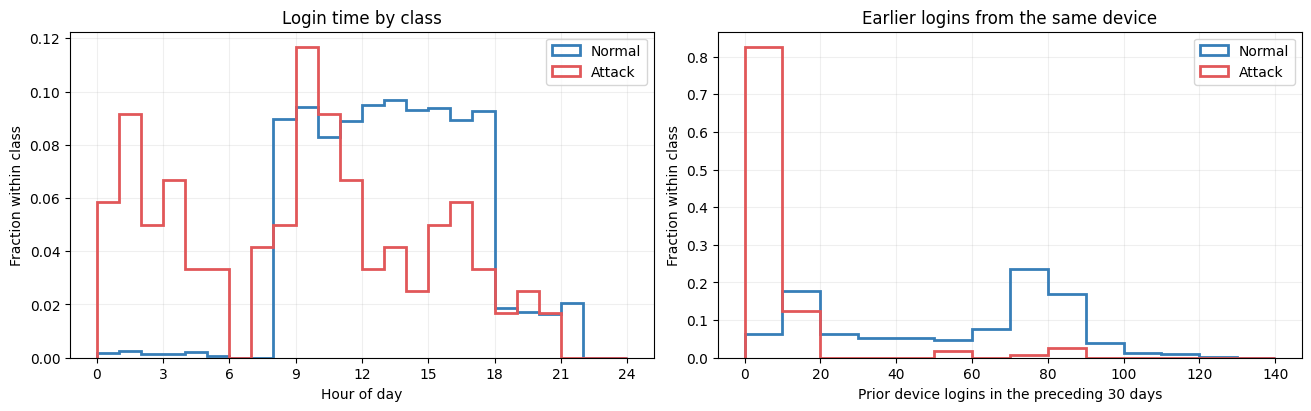

In [7]:
fig, axes = plt.subplots(
    1, 2, figsize=(13, 4), layout="constrained"
)

for label, name, color in [
    (0, "Normal", "#377eb8"),
    (1, "Attack", "#e15759"),
]:
    group = df.loc[df["is_attack"].eq(label)]

    axes[0].hist(
        group["hour"],
        bins=np.arange(0, 25),
        weights=np.ones(len(group)) / len(group),
        histtype="step",
        linewidth=2,
        label=name,
        color=color,
    )

    axes[1].hist(
        group["prior_device_logins_30d"],
        bins=np.arange(0, 141, 10),
        weights=np.ones(len(group)) / len(group),
        histtype="step",
        linewidth=2,
        label=name,
        color=color,
    )

axes[0].set(
    title="Login time by class",
    xlabel="Hour of day",
    ylabel="Fraction within class",
    xticks=range(0, 25, 3),
)

axes[1].set(
    title="Earlier logins from the same device",
    xlabel="Prior device logins in the preceding 30 days",
    ylabel="Fraction within class",
)

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)

plt.show()

### EDA observations

Normal logins occur mainly during working hours, with some
legitimate evening and nighttime activity. Attacks also occur
during working hours, so login time alone cannot distinguish
malicious activity from normal behavior.

Attack events are concentrated in the lowest device-history
range (0–9 prior logins). However, legitimate events also appear
in this range, particularly when employees start using new devices.
Some attacks use established devices and overlap with normal activity.

Expected normal behavior includes familiar devices, working-hour
access, and few failed password attempts. Potential anomalies
include combinations of unusual timing, limited device history,
and repeated failures. No individual feature confirms an attack.

These patterns reflect our synthetic generation assumptions.
They do not establish how real-world attacks are distributed.

## 3. Chronological Train, Validation, and Test Split

The 60-day experiment is divided into 36 training days,
12 validation days, and 12 test days.

The autoencoder will learn only from normal training records.
Normal validation records will be used for early stopping
and threshold selection. The test partition is reserved for
final evaluation.

Preprocessing will be fitted on training data only.
Historical features use strictly earlier events and require
no attack labels.

In [8]:
train_end = experiment_start + pd.Timedelta(days=36)
validation_end = experiment_start + pd.Timedelta(days=48)

df["split"] = np.select(
    [
        df["timestamp"] < train_end,
        df["timestamp"] < validation_end,
    ],
    ["train", "validation"],
    default="test",
)

train_df = df.loc[df["split"].eq("train")].copy()
val_df = df.loc[df["split"].eq("validation")].copy()
test_df = df.loc[df["split"].eq("test")].copy()

# Required normal-only data for the autoencoder.
normal_train_df = train_df.loc[
    train_df["is_attack"].eq(0)
].copy()

normal_val_df = val_df.loc[
    val_df["is_attack"].eq(0)
].copy()

split_summary = pd.crosstab(
    df["split"], df["is_attack"]
).reindex(
    index=["train", "validation", "test"],
    columns=[0, 1],
    fill_value=0,
)

split_summary.columns = ["Normal", "Attack"]
split_summary["Total"] = split_summary.sum(axis=1)
split_summary["Attack percentage"] = (
    100 * split_summary["Attack"] / split_summary["Total"]
).round(2)

display(split_summary)

assert len(train_df) + len(val_df) + len(test_df) == N_EXPERIMENT

assert (
    train_df["timestamp"].max()
    < val_df["timestamp"].min()
)
assert (
    val_df["timestamp"].max()
    < test_df["timestamp"].min()
)

assert len(normal_train_df) > 0
assert len(normal_val_df) > 0
assert test_df["is_attack"].nunique() == 2

print("Normal-only AE training records:", len(normal_train_df))
print("Normal-only AE validation records:", len(normal_val_df))
print("Chronological split checks passed.")

,Normal,Attack,Total,Attack percentage
split,,,,
train,2274,66,2340,2.82
validation,750,27,777,3.47
test,856,27,883,3.06


Normal-only AE training records: 2274
Normal-only AE validation records: 750
Chronological split checks passed.


## 4. Model A — Isolation Forest

Numeric features are standardized, and device type is one-hot
encoded. Preprocessing is fitted only on the training partition.

Isolation Forest learns from the full training partition without
using attack labels. We set contamination to 0.03 based on the
declared synthetic dataset design.

Scores are negated so that higher values indicate more unusual
events. These scores are not probabilities of an attack.

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    confusion_matrix,
    precision_recall_fscore_support,
)

if_preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_cols),
    ("categorical", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False,
    ), categorical_cols),
])

X_if_train = if_preprocessor.fit_transform(
    train_df[feature_cols]
)
X_if_test = if_preprocessor.transform(
    test_df[feature_cols]
)

iso = IsolationForest(
    n_estimators=300,
    contamination=0.03,
    random_state=SEED,
    n_jobs=-1,
)
iso.fit(X_if_train)

# Negate decision_function: higher means more unusual.
if_score = -iso.decision_function(X_if_test)
if_pred = (iso.predict(X_if_test) == -1).astype(int)

y_test = test_df["is_attack"].to_numpy()

tn, fp, fn, tp = confusion_matrix(
    y_test, if_pred, labels=[0, 1]
).ravel()

precision, recall, f1, _ = precision_recall_fscore_support(
    y_test,
    if_pred,
    average="binary",
    zero_division=0,
)

display(pd.DataFrame([{
    "Model": "Isolation Forest",
    "Detected anomalies": int(if_pred.sum()),
    "Alert percentage": round(100 * if_pred.mean(), 2),
    "Precision": round(precision, 3),
    "Recall": round(recall, 3),
    "F1": round(f1, 3),
    "True positives": int(tp),
    "False positives": int(fp),
    "False negatives": int(fn),
    "True negatives": int(tn),
}]))

display(pd.DataFrame(
    [[tn, fp], [fn, tp]],
    index=["Actual normal", "Actual attack"],
    columns=["Predicted normal", "Predicted attack"],
))

,Model,Detected anomalies,Alert percentage,Precision,Recall,F1,True positives,False positives,False negatives,True negatives
0,Isolation Forest,25,2.83,0.48,0.444,0.462,12,13,15,843


,Predicted normal,Predicted attack
Actual normal,843,13
Actual attack,15,12


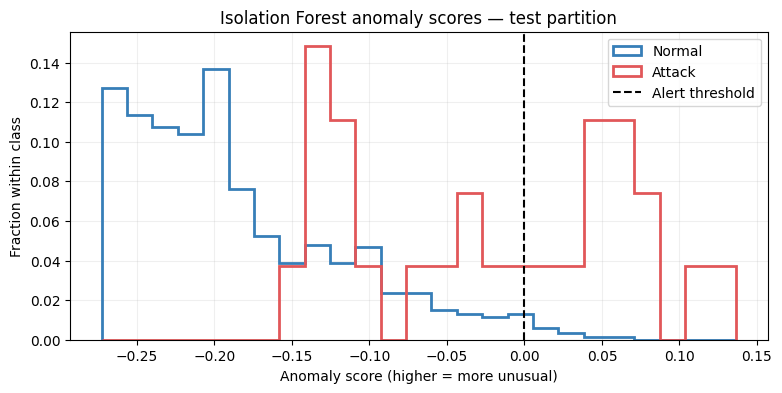

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))

for label, name, color in [
    (0, "Normal", "#377eb8"),
    (1, "Attack", "#e15759"),
]:
    scores = if_score[y_test == label]

    ax.hist(
        scores,
        bins=np.linspace(if_score.min(), if_score.max(), 26),
        weights=np.ones(len(scores)) / len(scores),
        histtype="step",
        linewidth=2,
        label=name,
        color=color,
    )

ax.axvline(
    0,
    color="black",
    linestyle="--",
    label="Alert threshold",
)

ax.set(
    title="Isolation Forest anomaly scores — test partition",
    xlabel="Anomaly score (higher = more unusual)",
    ylabel="Fraction within class",
)
ax.legend()
ax.grid(alpha=0.2)
plt.show()

### Isolation Forest results

Isolation Forest raised 25 alerts on 883 test events.
It detected 12 of 27 attacks and missed 15 attacks.
There were 13 false positives among 856 normal events.

Attack-class precision was 0.480, recall was 0.444,
and F1 was 0.462. These results indicate that the current
configuration misses a substantial proportion of attacks
and also flags some legitimate activity.

The test results are reported without tuning parameters
on the test partition. Individual errors will be investigated
after comparison with the autoencoder.

## 5. Model B — Autoencoder with Categorical Embeddings

The autoencoder combines standardized numeric features with
a trainable embedding for device type.

It will reconstruct numeric inputs and predict the original
device category. Training will use only normal training events.
Normal validation events will support early stopping and
threshold selection.

In [11]:
import os
import sys
import subprocess
import importlib.util
import importlib.metadata

try:
    keras_major = int(
        importlib.metadata.version("keras").split(".")[0]
    )
except importlib.metadata.PackageNotFoundError:
    keras_major = 0

packages = []

if keras_major < 3:
    packages.append("keras>=3,<4")

if importlib.util.find_spec("torch") is None:
    packages.append("torch")

if packages:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", *packages
    ])

os.environ["KERAS_BACKEND"] = "torch"

import keras
import torch
from keras import layers

assert keras.backend.backend() == "torch", (
    "Restart the session, then run this cell before importing Keras."
)

keras.utils.set_random_seed(SEED)
torch.set_num_threads(1)

print("Keras:", keras.__version__)
print("PyTorch:", torch.__version__)
print("Backend:", keras.backend.backend())
print("Autoencoder environment ready.")

Keras: 3.13.2
PyTorch: 2.14.1+cpu
Backend: torch
Autoencoder environment ready.


In [12]:
# Fit numeric scaling on normal training events only.
ae_scaler = StandardScaler()
ae_scaler.fit(normal_train_df[numeric_cols])

# Category 0 is reserved for values unseen in normal training data.
category_maps = {}
category_sizes = {}

for col in categorical_cols:
    values = sorted(normal_train_df[col].unique())

    category_maps[col] = {
        value: i + 1 for i, value in enumerate(values)
    }
    category_sizes[col] = len(values) + 1


def prepare_ae_frame(frame):
    numeric = ae_scaler.transform(
        frame[numeric_cols]
    ).astype("float32")

    inputs = {"numeric": numeric}
    targets = {"numeric_out": numeric}

    for col in categorical_cols:
        codes = (
            frame[col]
            .map(category_maps[col])
            .fillna(0)
            .to_numpy(dtype="int32")
        )

        inputs[col] = codes
        targets[f"{col}_out"] = codes

    return inputs, targets


ae_train_inputs, ae_train_targets = prepare_ae_frame(
    normal_train_df
)
ae_val_inputs, ae_val_targets = prepare_ae_frame(
    normal_val_df
)
ae_test_inputs, ae_test_targets = prepare_ae_frame(
    test_df
)

print("Category mappings:", category_maps)

for name, inputs in [
    ("Normal train", ae_train_inputs),
    ("Normal validation", ae_val_inputs),
    ("Full test", ae_test_inputs),
]:
    print(f"\n{name}:")
    for feature, values in inputs.items():
        print(f"  {feature}: shape={values.shape}, dtype={values.dtype}")

    assert np.isfinite(inputs["numeric"]).all()

print("\nAutoencoder inputs ready.")

Category mappings: {'device_type': {'laptop': 1, 'phone': 2}}

Normal train:
  numeric: shape=(2274, 4), dtype=float32
  device_type: shape=(2274,), dtype=int32

Normal validation:
  numeric: shape=(750, 4), dtype=float32
  device_type: shape=(750,), dtype=int32

Full test:
  numeric: shape=(883, 4), dtype=float32
  device_type: shape=(883,), dtype=int32

Autoencoder inputs ready.


In [13]:
keras.utils.set_random_seed(SEED)

numeric_input = layers.Input(
    shape=(len(numeric_cols),),
    name="numeric",
)

model_inputs = {"numeric": numeric_input}
parts = [numeric_input]

for col in categorical_cols:
    category_input = layers.Input(
        shape=(),
        dtype="int32",
        name=col,
    )
    model_inputs[col] = category_input

    embedding = layers.Embedding(
        input_dim=category_sizes[col],
        output_dim=2,
        name=f"{col}_embedding",
    )(category_input)

    parts.append(embedding)

combined = layers.Concatenate(
    name="combined_features"
)(parts)

hidden = layers.Dense(
    16, activation="relu", name="encoder_hidden"
)(combined)

latent = layers.Dense(
    3, activation="linear", name="behavior_embedding"
)(hidden)

decoded = layers.Dense(
    16, activation="relu", name="decoder_hidden"
)(latent)

model_outputs = {
    "numeric_out": layers.Dense(
        len(numeric_cols),
        name="numeric_out",
    )(decoded)
}

for col in categorical_cols:
    model_outputs[f"{col}_out"] = layers.Dense(
        category_sizes[col],
        activation="softmax",
        name=f"{col}_out",
    )(decoded)

autoencoder = keras.Model(
    inputs=model_inputs,
    outputs=model_outputs,
    name="login_autoencoder",
)

encoder = keras.Model(
    inputs=model_inputs,
    outputs=latent,
    name="login_encoder",
)

losses = {"numeric_out": "mse"}
loss_weights = {"numeric_out": 1.0}

for col in categorical_cols:
    losses[f"{col}_out"] = "sparse_categorical_crossentropy"
    loss_weights[f"{col}_out"] = 0.35

autoencoder.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=losses,
    loss_weights=loss_weights,
)

autoencoder.summary()

Model: "login_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ device_type         │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ numeric             │ (None, 4)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ device_type_embedd… │ (None, 2)         │          6 │ device_type[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ combined_features   │ (None, 6)         │          0 │ numeric[0][0],    │
│ (Concatenate)       │                   │            │ device_type_embe… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_hidden      │ (None, 16)        │        112 │ combined_feature… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ behavior_embedding  │ (None, 3)         │         51 │ encoder_hidden[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_hidden      │ (None, 16)        │         64 │ behavior_embeddi… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ device_type_out     │ (None, 3)         │         51 │ decoder_hidden[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ numeric_out (Dense) │ (None, 4)         │         68 │ decoder_hidden[0… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 352 (1.38 KB)

 Trainable params: 352 (1.38 KB)

 Non-trainable params: 0 (0.00 B)

Epochs completed: 100
Lowest recorded validation loss: 0.04308


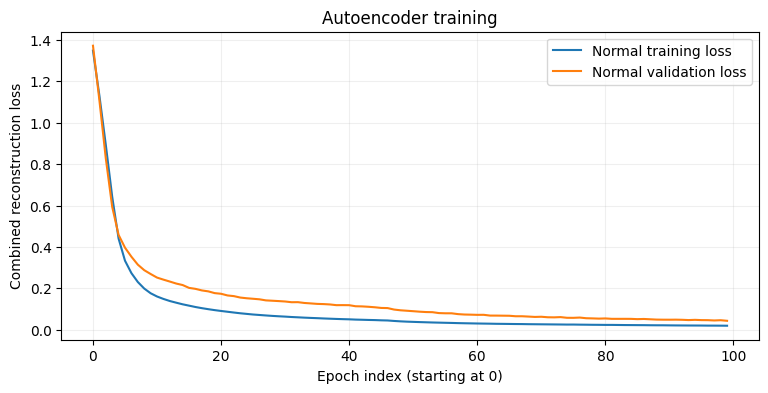

In [14]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    min_delta=0.0001,
    restore_best_weights=True,
)

history = autoencoder.fit(
    ae_train_inputs,
    ae_train_targets,
    validation_data=(ae_val_inputs, ae_val_targets),
    epochs=100,
    batch_size=64,
    callbacks=[early_stopping],
    shuffle=True,
    verbose=0,
)

train_losses = np.array(history.history["loss"])
val_losses = np.array(history.history["val_loss"])

assert np.isfinite(train_losses).all()
assert np.isfinite(val_losses).all()

print("Epochs completed:", len(train_losses))
print("Lowest recorded validation loss:", round(val_losses.min(), 5))

plt.figure(figsize=(9, 4))
plt.plot(train_losses, label="Normal training loss")
plt.plot(val_losses, label="Normal validation loss")
plt.xlabel("Epoch index (starting at 0)")
plt.ylabel("Combined reconstruction loss")
plt.title("Autoencoder training")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [15]:
def ae_anomaly_scores(model, inputs, targets):
    predictions = model.predict(inputs, verbose=0)

    numeric_error = np.mean(
        np.square(
            targets["numeric_out"] - predictions["numeric_out"]
        ),
        axis=1,
    )

    categorical_error = np.zeros(
        len(numeric_error), dtype="float32"
    )

    for col in categorical_cols:
        true_codes = targets[f"{col}_out"]
        probabilities = predictions[f"{col}_out"]

        true_probabilities = probabilities[
            np.arange(len(true_codes)), true_codes
        ]

        categorical_error += -np.log(
            np.clip(true_probabilities, 1e-8, 1.0)
        )

    # Match the weighted reconstruction losses used in training.
    return numeric_error + 0.35 * categorical_error


normal_val_score = ae_anomaly_scores(
    autoencoder, ae_val_inputs, ae_val_targets
)

threshold = float(np.percentile(normal_val_score, 99))

ae_score = ae_anomaly_scores(
    autoencoder, ae_test_inputs, ae_test_targets
)
ae_pred = (ae_score > threshold).astype(int)

assert np.isfinite(normal_val_score).all()
assert np.isfinite(ae_score).all()

tn, fp, fn, tp = confusion_matrix(
    y_test, ae_pred, labels=[0, 1]
).ravel()

precision, recall, f1, _ = precision_recall_fscore_support(
    y_test, ae_pred, average="binary", zero_division=0
)

print("AE threshold:", round(threshold, 6))
print(
    "Normal validation records above threshold:",
    f"{np.mean(normal_val_score > threshold):.2%}",
)

display(pd.DataFrame([{
    "Model": "Autoencoder + embeddings",
    "Detected anomalies": int(ae_pred.sum()),
    "Alert percentage": round(100 * ae_pred.mean(), 2),
    "Precision": round(precision, 3),
    "Recall": round(recall, 3),
    "F1": round(f1, 3),
    "True positives": int(tp),
    "False positives": int(fp),
    "False negatives": int(fn),
    "True negatives": int(tn),
}]))

display(pd.DataFrame(
    [[tn, fp], [fn, tp]],
    index=["Actual normal", "Actual attack"],
    columns=["Predicted normal", "Predicted attack"],
))

AE threshold: 0.669697
Normal validation records above threshold: 1.07%


,Model,Detected anomalies,Alert percentage,Precision,Recall,F1,True positives,False positives,False negatives,True negatives
0,Autoencoder + embeddings,10,1.13,0.6,0.222,0.324,6,4,21,852


,Predicted normal,Predicted attack
Actual normal,852,4
Actual attack,21,6


## 6. Quantitative Comparison

Both models are evaluated on the same 883 test events,
including 27 attacks.

We compare their configured thresholds using precision,
recall, F1, false positives, false negatives, and agreement.
Agreement measures consistency between predictions,
not their correctness.

In [16]:
def model_metrics(name, predictions):
    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, predictions,
        average="binary",
        zero_division=0,
    )

    return {
        "Model": name,
        "Detected anomalies": int(predictions.sum()),
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "False positives": int(fp),
        "False negatives": int(fn),
    }


comparison = pd.DataFrame([
    model_metrics("Isolation Forest", if_pred),
    model_metrics("Autoencoder + embeddings", ae_pred),
]).set_index("Model")

display(comparison.round(3))

both = (if_pred == 1) & (ae_pred == 1)
if_only = (if_pred == 1) & (ae_pred == 0)
ae_only = (if_pred == 0) & (ae_pred == 1)

print(f"Agreement rate: {np.mean(if_pred == ae_pred):.2%}")
print("Flagged by both:", int(both.sum()))
print("Isolation Forest only:", int(if_only.sum()))
print("Autoencoder only:", int(ae_only.sum()))
print("Neither model:", int(((if_pred == 0) & (ae_pred == 0)).sum()))

,Detected anomalies,Precision,Recall,F1,False positives,False negatives
Model,,,,,,
Isolation Forest,25,0.48,0.444,0.462,13,15
Autoencoder + embeddings,10,0.60,0.222,0.324,4,21


Agreement rate: 98.07%
Flagged by both: 9
Isolation Forest only: 16
Autoencoder only: 1
Neither model: 857


In [17]:
results = test_df.copy()
results["if_score"] = if_score
results["ae_score"] = ae_score
results["if_pred"] = if_pred
results["ae_pred"] = ae_pred

results["detection_group"] = np.select(
    [both, if_only, ae_only],
    ["Both models", "Isolation Forest only", "Autoencoder only"],
    default="Neither model",
)

group_summary = pd.crosstab(
    results["detection_group"], results["is_attack"]
).reindex(
    index=["Both models", "Isolation Forest only", "Autoencoder only", "Neither model"],
    columns=[0, 1], fill_value=0,
)
group_summary.columns = ["Normal", "Attack"]
display(group_summary)

print("Autoencoder-only event:")
display(results.loc[
    results["detection_group"].eq("Autoencoder only"),
    ["event_id", "timestamp", "user_id", "device_id", "device_type",
     "is_weekend", "failed_attempts_30m", "prior_device_logins_30d",
     "is_attack", "scenario", "if_score", "ae_score"],
])

# Retrospective evaluation only: scenario and labels are not model inputs.
attack_results = results.loc[results["is_attack"].eq(1)]
scenario_summary = attack_results.groupby("scenario").agg(
    test_attacks=("event_id", "size"),
    IF_detected=("if_pred", "sum"),
    AE_detected=("ae_pred", "sum"),
)
print("Detection coverage by synthetic attack scenario:")
display(scenario_summary)
print("Attack scenarios by detection group:")
display(pd.crosstab(attack_results["scenario"], attack_results["detection_group"]))

# Verify which partition contains the single tablet example.
print("Tablet events and their data partitions:")
display(df.loc[df["device_type"].eq("tablet"),
               ["event_id", "timestamp", "split", "is_attack"]])

# Report the completed training run without retraining the network.
best_epoch = int(np.argmin(val_losses))
print("Epochs completed:", len(val_losses))
print("Lowest validation loss at epoch index:", best_epoch)
print("Early stopping triggered:", early_stopping.stopped_epoch > 0)


,Normal,Attack
detection_group,,
Both models,4,5
Isolation Forest only,9,7
Autoencoder only,0,1
Neither model,843,14


Autoencoder-only event:


,event_id,timestamp,user_id,device_id,device_type,is_weekend,failed_attempts_30m,prior_device_logins_30d,is_attack,scenario,if_score,ae_score
3621,login_05621,2026-10-26 10:19:00,user_16,user_16_unfamiliar_106,laptop,0,3,0,1,unfamiliar_device,-0.067974,0.778759


Detection coverage by synthetic attack scenario:


,test_attacks,IF_detected,AE_detected
scenario,,,
night_intrusion,9,9,5
routine_like_attack,10,0,0
unfamiliar_device,8,3,1


Attack scenarios by detection group:


detection_group,Autoencoder only,Both models,Isolation Forest only,Neither model
scenario,,,,
night_intrusion,0,5,4,0
routine_like_attack,0,0,0,10
unfamiliar_device,1,0,3,4


Tablet events and their data partitions:


,event_id,timestamp,split,is_attack
2545,login_04545,2026-10-10 02:10:00,validation,1


Epochs completed: 100
Lowest validation loss at epoch index: 99
Early stopping triggered: False


### Comparison findings

Isolation Forest achieved higher recall and F1, while the
autoencoder achieved higher precision and fewer false positives
at the configured thresholds.

The models agreed on 98.07% of test events. However, they jointly
missed 14 attacks and jointly flagged four normal events.
Agreement therefore does not establish correctness.

The autoencoder uniquely detected one attack: login_05621,
at 10:19, with three preceding failed attempts and no earlier
logins from that device. Isolation Forest did not flag it.

These observations suggest complementary sensitivity in this
run. They do not establish which features caused either score.

Preprocessed input space: variance retained by 2 PCs = 55.0%
AE latent space: variance retained by 2 PCs = 87.6%


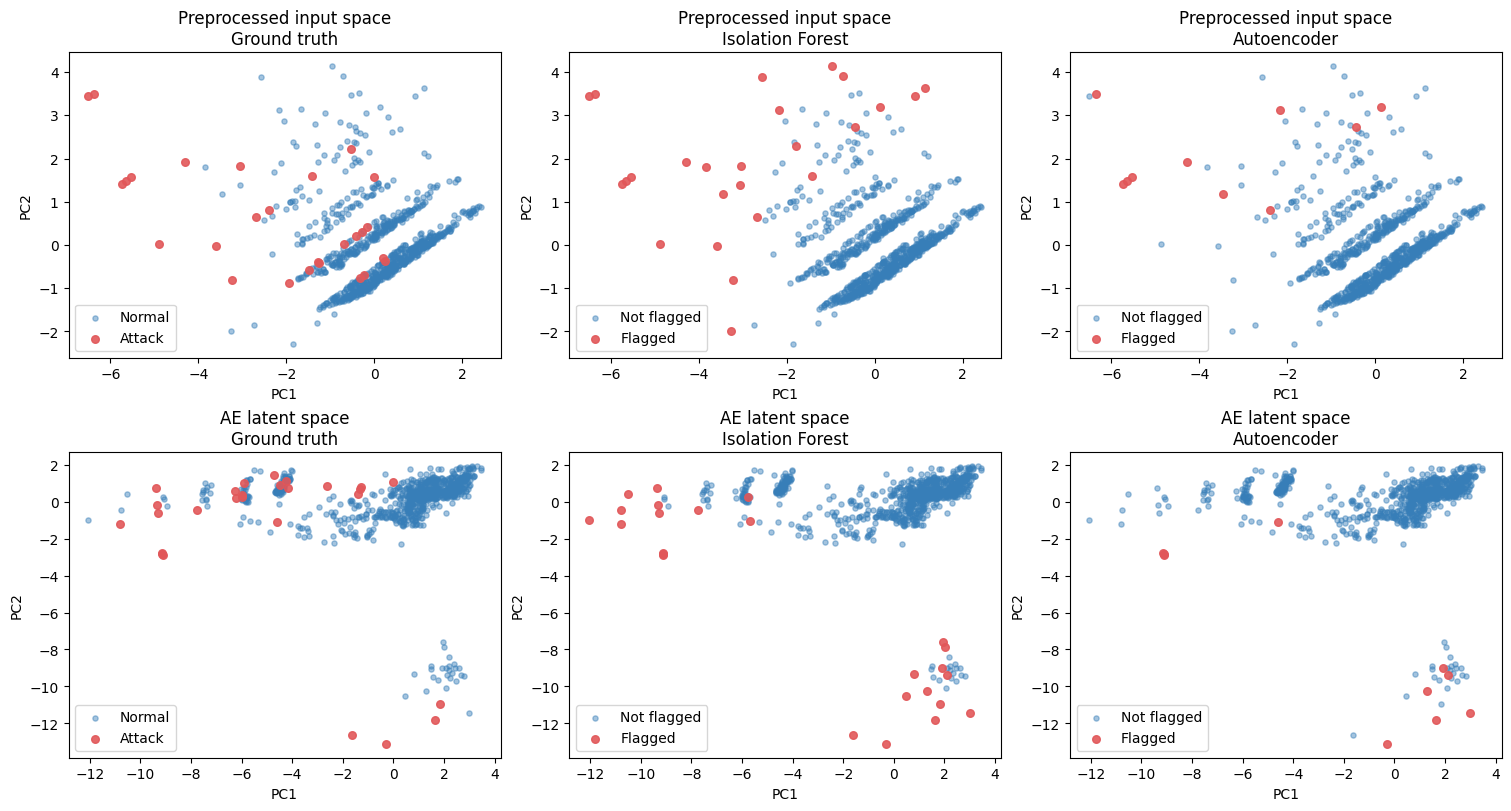

In [18]:
from sklearn.decomposition import PCA

latent_test = encoder.predict(ae_test_inputs, verbose=0)

fig, axes = plt.subplots(
    2, 3, figsize=(15, 8), layout="constrained"
)

for row, matrix, space_name in zip(
    axes,
    [X_if_test, latent_test],
    ["Preprocessed input space", "AE latent space"],
):
    pca = PCA(n_components=2)
    coordinates = pca.fit_transform(matrix)

    for ax, labels, title in zip(
        row,
        [y_test, if_pred, ae_pred],
        ["Ground truth", "Isolation Forest", "Autoencoder"],
    ):
        for value, color in [(0, "#377eb8"), (1, "#e15759")]:
            mask = labels == value

            legend = (
                ["Normal", "Attack"][value]
                if title == "Ground truth"
                else ["Not flagged", "Flagged"][value]
            )

            ax.scatter(
                coordinates[mask, 0],
                coordinates[mask, 1],
                s=14 if value == 0 else 30,
                alpha=0.45 if value == 0 else 0.9,
                color=color,
                label=legend,
            )

        ax.set(
            title=f"{space_name}\n{title}",
            xlabel="PC1",
            ylabel="PC2",
        )
        ax.legend()

    print(
        f"{space_name}: variance retained by 2 PCs = "
        f"{pca.explained_variance_ratio_.sum():.1%}"
    )

plt.show()

### Interpretation of the PCA plots

The first two principal components retain 55.0% of variance
in the preprocessed input space and 87.6% in the three-dimensional
autoencoder latent space. These percentages refer to different
representations and do not measure class separation.

In both projections, some attacks appear away from the main
normal clusters, while others overlap with legitimate events.
The latent representation does not visually provide complete
separation between normal and malicious activity.

The plots do not demonstrate that embeddings improved detection.
An autoencoder without embeddings would be needed as a comparison
to isolate their contribution.

PCA is a visualization tool. Isolation Forest scores its full
input space, while the autoencoder scores reconstruction error,
not distance in the two-dimensional plot.

In [19]:
case_ae_attack = results.loc[
    (results["ae_pred"] == 1)
    & (results["if_pred"] == 0)
    & (results["is_attack"] == 1)
].nlargest(1, "ae_score")

case_if_attack = results.loc[
    (results["if_pred"] == 1)
    & (results["ae_pred"] == 0)
    & (results["is_attack"] == 1)
].nlargest(1, "if_score")

case_if_normal = results.loc[
    (results["if_pred"] == 1)
    & (results["ae_pred"] == 0)
    & (results["is_attack"] == 0)
].nlargest(1, "if_score")

selected_cases = pd.concat([
    case_ae_attack,
    case_if_attack,
    case_if_normal,
])

assert len(selected_cases) == 3
assert selected_cases["event_id"].is_unique

display(selected_cases[[
    "event_id", "timestamp", "user_id",
    "device_type", "is_weekend",
    "failed_attempts_30m", "prior_device_logins_30d",
    "if_score", "ae_score", "if_pred", "ae_pred",
    "is_attack", "scenario",
]])

,event_id,timestamp,user_id,device_type,is_weekend,failed_attempts_30m,prior_device_logins_30d,if_score,ae_score,if_pred,ae_pred,is_attack,scenario
3621,login_05621,2026-10-26 10:19:00,user_16,laptop,0,3,0,-0.067974,0.778759,0,1,1,unfamiliar_device
3508,login_05508,2026-10-24 01:37:00,user_06,phone,1,5,0,0.136342,0.618498,1,0,1,night_intrusion
3319,login_05319,2026-10-21 08:41:00,user_20,phone,0,5,15,0.031691,0.027873,1,0,0,routine


## 7. Analysis of Model Disagreements

### Case 1 — login_05621: Autoencoder-only alert

**Observed evidence:** The login occurred on Monday at 10:19
from a laptop, after three failed attempts. There were no earlier
logins from this device within the preceding 30 days.

**Model disagreement:** The autoencoder score was 0.778759,
above its threshold of 0.669697. Isolation Forest did not flag
the event (score −0.067974; alert threshold 0).

**Decision: Escalate for additional verification.**
Check whether IT issued a new laptop and confirm the login
with the employee through a trusted channel. Review MFA records
if available. These checks have not been performed in this lab.

**Possible legitimate explanation:** The employee received
a new laptop and mistyped the password before logging in.

**MITRE ATT&CK:** T1078 — Valid Accounts is an investigation
hypothesis. The observed features alone do not confirm misuse.
The synthetic ground-truth label identifies this event as an
attack, but that label would not be available to an analyst.

The scores alone do not establish which features caused
the models to disagree.

### Case 2 — login_05508: Isolation-Forest-only alert

**Observed evidence:** The successful login occurred on Saturday
at 01:37 from a phone, after five failed attempts. The account
had no earlier logins from this device in the preceding 30 days.

**Model disagreement:** Isolation Forest flagged the event
(score 0.136342; threshold 0). The autoencoder did not:
its score of 0.618498 was below the threshold of 0.669697.

**Decision: Escalate for additional verification.**
Verify whether the employee authorized this nighttime access
and recognizes the device. Review MFA results and activity
following the login, if available. These checks have not
been performed in this lab.

**Possible legitimate explanation:** The employee needed urgent
weekend access from a new phone and mistyped the password.

**MITRE ATT&CK:** T1078 — Valid Accounts is a relevant hypothesis.
Repeated failures also warrant investigating possible password
guessing, but do not independently confirm T1110 — Brute Force.

The synthetic label identifies this event as an attack.
The reason for the models' disagreement has not been established
through feature attribution.

### Case 3 — login_05319: Isolation-Forest-only false positive

**Observed evidence:** The login occurred on Wednesday at 08:41
from a phone, after five failed attempts. The same account-device
pair had 15 successful logins during the preceding 30 days.

**Model disagreement:** Isolation Forest flagged the event
(score 0.031691; threshold 0). The autoencoder did not
(score 0.027873; threshold 0.669697).

**Decision: Challenge the alert and verify with the employee.**
Working-hour access and established device history support
a legitimate explanation, while five failed attempts warrant
verification through a trusted channel.

If the employee confirms the login and supporting records
are consistent, close the alert as a false positive.
If the employee denies it, escalate for account protection
and credential reset according to organizational procedures.
These follow-up checks have not been performed in this lab.

**Possible legitimate explanation:** The employee mistyped
or forgot the password before successfully accessing the account.

**MITRE ATT&CK:** T1078 — Valid Accounts remains an investigation
hypothesis, not a confirmed finding. Five failed attempts alone
do not establish T1110 — Brute Force.

The synthetic label identifies this event as normal.
The model score alone does not prove which feature caused
the alert.

In [20]:
results["review_rank"] = results[
    ["if_score", "ae_score"]
].rank(pct=True).max(axis=1)

high_alerts = (
    results.loc[results["if_pred"].eq(1) | results["ae_pred"].eq(1)]
    .sort_values(["review_rank", "event_id"], ascending=[False, True])
    .head(3)
)

display(high_alerts[[
    "event_id", "timestamp", "user_id", "device_id", "device_type",
    "is_weekend", "failed_attempts_30m", "prior_device_logins_30d",
    "if_score", "ae_score", "if_pred", "ae_pred", "is_attack", "scenario",
]])


,event_id,timestamp,user_id,device_id,device_type,is_weekend,failed_attempts_30m,prior_device_logins_30d,if_score,ae_score,if_pred,ae_pred,is_attack,scenario
3508,login_05508,2026-10-24 01:37:00,user_06,user_06_unfamiliar_002,phone,1,5,0,0.136342,0.618498,1,0,1,night_intrusion
3514,login_05514,2026-10-24 20:37:00,user_14,user_14_phone,phone,1,0,12,0.063053,2.723459,1,1,0,evening_work
3496,login_05496,2026-10-23 01:21:00,user_14,user_14_unfamiliar_095,laptop,1,5,0,0.109905,1.883118,1,1,1,night_intrusion


## 8. Human–AI Decisions for High-Scoring Alerts

Events were prioritized by the maximum of their percentile
ranks within the two models. Raw scores were not compared
directly because the models use different scoring scales.

### Alert 1 — login_05508

**Evidence:** Saturday, 01:37; phone; five failed attempts;
no prior logins from this device in the preceding 30 days.
Only Isolation Forest flagged the event.

**Decision:** Escalate for verification, as discussed in Case 2.
Check employee authorization, device recognition, MFA records,
and activity following the login.

**Benign alternative:** Urgent weekend work from a new phone.

**MITRE ATT&CK:** Possible T1078 — Valid Accounts.
The synthetic label identifies an attack, but the available
observations alone do not confirm account compromise.

### Alert 2 — login_05514

**Evidence:** Saturday, 20:37; phone; zero failed attempts;
12 prior logins from this device in the preceding 30 days.
Both models flagged the event.

**Decision:** Verify the evening access with the employee
through a trusted channel. If confirmed and consistent with
supporting records, close the alert. If denied, escalate
for investigation.

**Benign alternative:** Authorized evening work on a weekend.

**MITRE ATT&CK:** T1078 — Valid Accounts is a hypothesis
to investigate, not a confirmed technique.

**Evaluation:** The synthetic label identifies a normal event,
making this a false positive for both models. Model agreement
does not establish maliciousness.

These proposed follow-up checks have not been performed.

### Alert 3 — login_05496

**Evidence:** Friday, 01:21; laptop; five failed attempts;
no prior logins from this device in the preceding 30 days.
Both models flagged the event.

**Decision:** Escalate for verification. Confirm whether the
employee authorized the login and recognizes the laptop.
Review MFA records and subsequent account activity, if available.
These checks have not been performed in this lab.

**Benign alternative:** Urgent weekend work from a new laptop,
with password mistakes before successful authentication.

**MITRE ATT&CK:** Possible T1078 — Valid Accounts.
Repeated failures warrant investigating password guessing,
but do not independently confirm T1110 — Brute Force.

**Evaluation:** The synthetic label identifies an attack.
Agreement between the models supports prioritizing review,
but does not independently prove compromise.

## 9. Conclusion

### Which model performed better?

On this synthetic test set, Isolation Forest achieved higher recall (0.444 versus 0.222) and F1 (0.462 versus 0.324). The autoencoder achieved higher precision (0.600 versus 0.480). Neither model was best on every measure.

### Which model produced fewer false positives?

The autoencoder produced four false positives, compared with 13 for Isolation Forest. However, it missed 21 of 27 attacks, while Isolation Forest missed 15. Its smaller alert queue therefore came with lower attack coverage.

False-positive counts reflect both model behavior and threshold choices. Isolation Forest uses contamination=0.03 from the synthetic design, while the autoencoder uses the 99th percentile of normal validation scores. This comparison evaluates the configured systems rather than isolating model architecture.

### Which detections were unique to each model?

Isolation Forest uniquely flagged seven attacks and nine normal events. The autoencoder uniquely detected one attack: a working-hour laptop login with three failed attempts and no prior device history. Both models detected five attacks and jointly missed 14. Four normal events were flagged by both models.

The scenario-level table in Section 6 reports detection coverage by attack type. Isolation Forest detected 9 of 9 night_intrusion attacks and 3 of 8 unfamiliar_device attacks; the autoencoder detected 5 of 9 and 1 of 8, respectively. Neither model detected any of the 10 routine_like_attack events. Isolation Forest-only attacks comprised four night_intrusion and three unfamiliar_device events; the single autoencoder-only attack was unfamiliar_device.

The main blind spot was adversarial activity resembling normal working-hour access in the available features. These results reflect the generator's assumptions and do not establish real-world detection rates.

### Did embeddings improve behavioral separation?

The latent PCA retained 87.6% of its representation's variance, compared with 55.0% for the input-space PCA. These percentages do not measure class separation and are not directly comparable as evidence of improvement.

Both plots showed overlap between normal events and attacks. An improvement attributable to embeddings was not demonstrated; that would require a comparison with an autoencoder without embeddings.

### Why should an analyst avoid relying on one model alone?

The models detected different events, and their scores alone did not establish whether activity was malicious. Even agreement produced false positives. Analysts need independent context, such as device authorization, employee confirmation, MFA records, and subsequent activity, before deciding on a response.

### Limitations

Results cover one synthetic dataset, one chronological split, and 27 test attacks. The generator's assumptions may differ from real activity. Password-failure counts were sampled by scenario rather than reconstructed from individual failed-login logs; their distributions differ by construction. Device history and timing patterns also reflect the designed scenarios.

Only one attack used a tablet, and no normal event did. This event falls in the validation period and is excluded from normal-only validation, so it does not affect the selected threshold or test metrics. Unseen-category handling was not evaluated on the test set. The unknown-category embedding receives no training examples, so its behavior should not be interpreted as learned evidence of maliciousness.

Some routine_like_attack events reuse an existing account-device identifier. This assumes adversarial access through a previously used endpoint or session context; stolen credentials alone do not establish that access mechanism. Earlier attack events also contribute to subsequent device-history counts because the online feature does not have access to ground-truth labels. Normal behavior changes as employees receive replacement laptops.

The rare binary is_weekend feature is standardized alongside numeric inputs. Its scale can affect reconstruction loss; without per-feature error analysis, we cannot attribute a particular false positive to this feature.

Training reached the maximum of 100 epochs without triggering early stopping. Validation loss was still decreasing near the end. This does not establish whether additional training would improve attack detection.

Thresholds and model settings were not tuned on the test set. Additional seeds, independently designed scenarios, and matched alert budgets would be useful extensions before making broader performance claims.
